# Impacto de los factores de salud y estilo de vida en la calidad y duración del sueño.

---
# 8. Exploración de Variables
## 8.1. Prueba de Hipótesis 1
 *"A mayor nivel de estrés, menor es la calidad del sueño."*
* **Variables a considerar:** "Stress Level", "Quality of Sleep".

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df_limpio= pd.read_csv("../datos/df_limpio.csv")

In [10]:
df_h1 = df_limpio[["Stress Level", "Quality of Sleep"]].copy()
resultado_h1 = df_h1.groupby("Stress Level")["Quality of Sleep"].agg(["count","mean"])
print(resultado_h1.round(2))

              count  mean
Stress Level             
3                71  8.97
4                70  7.67
5                67  7.90
6                46  7.00
7                50  6.00
8                70  5.86


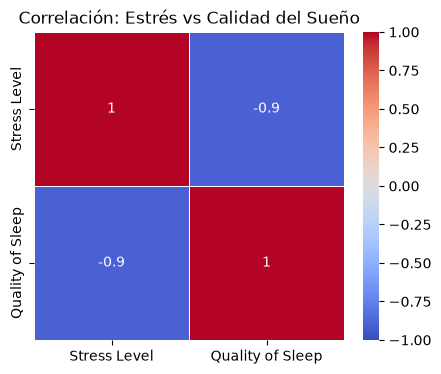

In [11]:

f, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(df_h1.corr(),
            annot=True,
            linewidths=.5,
            ax=ax,
            vmin=-1,
            vmax=1, 
            cmap = "coolwarm");
ax.set_title("Correlación: Estrés vs Calidad del Sueño")
plt.savefig("../imagen/correlacion_estres_calidad_sueno.jpg")
plt.show()


In [12]:
df_h1.corr(numeric_only=True)

,Stress Level,Quality of Sleep
Stress Level,1.000000,-0.898752
Quality of Sleep,-0.898752,1.000000


### *"A mayor nivel de estrés, menor es la calidad del sueño."*

Existe una correlación negativa "efecto espejo" muy fuerte (-0.90), a medida que sube el nivel de estrés, baja la calidad del sueño, respaldando la Hipótesis 1.

Observamos que la cantidad de datos para el análisis están repartidos de manera uniforme por lo que podemos concluir que la hipótesis es correcta, a menor nivel de estrés mayor es la calidad del sueño. Los niveles de estrés 3,4,5 es donde se concentra el mejor promedio de calidad de sueño, frente al nivel maximo de estrés (8) con una calidad promedio de sueño de 5.86

## 8.2. Prueba de Hipótesis 2
 *"Los hombres y las mujeres tienen una duración media de sueño diferente."*
* **Variables a considerar:** "Gender", "Sleep Duration".

In [13]:
df_h2 = df_limpio[["Gender", "Sleep Duration"]].copy()
resultado_h2 = df_h2.groupby("Gender")["Sleep Duration"].agg(["count","mean","median","std"])
resultado_h2.round(2)

,count,mean,median,std
Gender,,,,
Female,185,7.23,7.2,0.88
Male,189,7.04,7.2,0.69


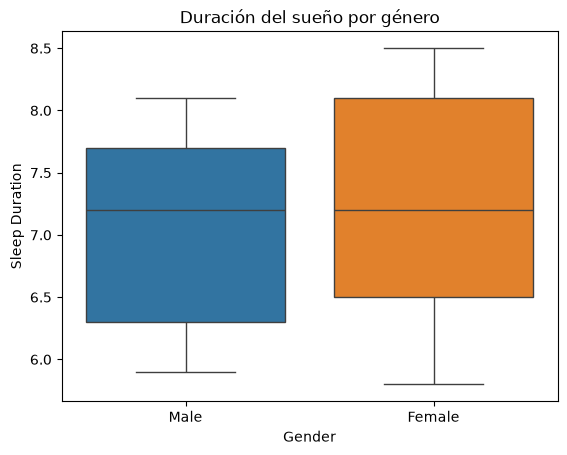

In [14]:
sns.boxplot(data=df_h2, x="Gender", y="Sleep Duration", hue="Gender")
plt.title("Duración del sueño por género")
plt.savefig("../imagen/duracion_sueno_genero.jpg")
plt.show()


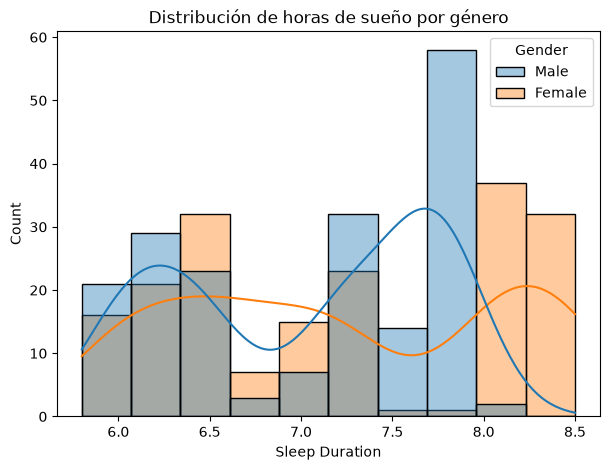

In [15]:
plt.figure(figsize=(7, 5))
sns.histplot(data=df_h2, x="Sleep Duration", hue="Gender", kde=True, alpha=0.4)
plt.title("Distribución de horas de sueño por género")
plt.savefig("../imagen/distribucion_horas_sueno_genero.jpg")
plt.show()

In [16]:
# Duración en minutos 
x = 7.23 - 7.04
x
minutos = x*60
minutos

11.400000000000023

### *"Los hombres y las mujeres tienen una duración media de sueño diferente."*
Podemos observar que los registros por género se encuentran repartidos de manera uniforme, encontrándose que la media de duración de sueño en las mujeres (7.23 horas) está ligeramente por encima del género masculino (7.04 horas).

La desviación estándar de los datos registrados en el género femenino corresponde a (0.88), lo que nos indica que se encuentran más dispersos y, por ende, registran mayor variabilidad en comparación con el género masculino (0.69).

En el gráfico "Duración del sueño por género" se puede visualizar que la mediana para ambos géneros tiene el mismo valor (7.2); sin embargo, la concentración de los mismos en el género femenino se encuentra en un rango más alto (7.2 a 8.0), en comparación con el género masculino, que está por debajo de la mediana en el rango de (6.5 a 7.2).

En el gráfico "Distribución de horas de sueño por género", vemos que la distribución de las horas de sueño en las mujeres se extiende más hasta 8.0 y 8.5 horas de sueño y podemos ver que ambas curvas se solapan en el centro.

Observamos que la diferencia de la media en minutos es relativamente pequeña siendo ésta de 11 minutos mayor en las mujeres con respecto a los hombres. 

Conclusión final de la Hipótesis: "Aunque la media de las mujeres es ligeramente superior (11 minutos), las medianas son iguales (7.2) y las curvas se solapan, por lo que la diferencia entre géneros es mínima y poco relevante en la práctica."

### 8.3. Prueba de Hipótesis 3
 *"Las personas con sobrepeso u obesidad tienen peor calidad de sueño que las personas con peso normal."*
* **Variables a considerar:** "BMI Category", "Quality of Sleep".

In [17]:
df_h3 = df_limpio[["BMI Category", "Quality of Sleep"]].copy()
resultado_h3 = df_h3.groupby("BMI Category")["Quality of Sleep"].agg(["count","mean","median","std"]).reindex(["Normal Weight", "Overweight", "Obese"])
resultado_h3.round(2)


,count,mean,median,std
BMI Category,,,,
Normal Weight,216,7.64,8.0,1.00
Overweight,148,6.90,6.0,1.25
Obese,10,6.40,7.0,1.90


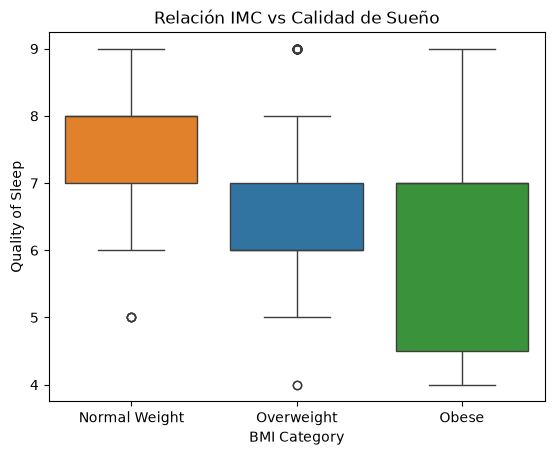

In [18]:
sns.boxplot(data=df_h3, x="BMI Category", y="Quality of Sleep", order=["Normal Weight", "Overweight", "Obese"],hue="BMI Category")
plt.title("Relación IMC vs Calidad de Sueño")
plt.savefig("../imagen/relacion_imc_calidad_sueno.jpg")
plt.show()

In [19]:
pd.crosstab(df_h3["BMI Category"], df_h3["Quality of Sleep"])

Quality of Sleep,4,5,6,7,8,9
BMI Category,,,,,,
Normal Weight,0,4,34,34,108,36
Obese,3,0,1,4,0,2
Overweight,2,3,70,39,1,33


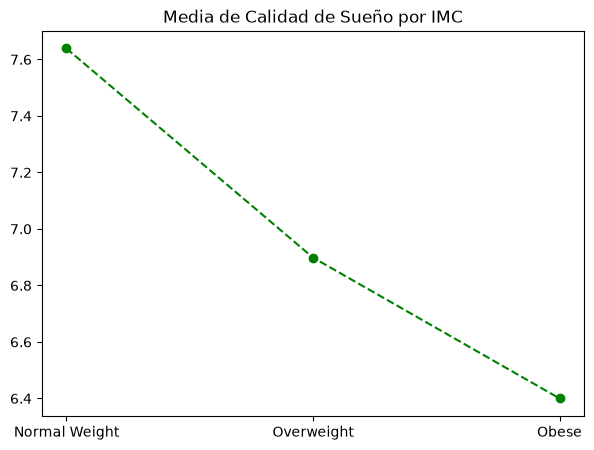

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(resultado_h3.index, resultado_h3["mean"], color='green', linestyle='--', marker='o')
ax.set_title("Media de Calidad de Sueño por IMC")
plt.savefig("../imagen/media_calidad_sueno_imc.jpg")
plt.show()

### "Las personas con sobrepeso u obesidad tienen peor calidad de sueño que las personas con peso normal."
Podemos visualizar que a medida que incrementa el IMC, la calidad del sueño cae notablemente (la mediana baja de 8 a 6), vemos en la categoria de Normal Weight, en torno a una calidad alta (mediana de 8) es donde se concentra el grupo con mejor descanso, también señalar que en la categoria Obese no existen outliers puesto que el numero de representación para dicha categoria es relativamente pequeño (10 registros), por lo que todos se situan dentro de la caja.
Los outliers de los otros grupos reflejan circunstancias excepcionales, ejemplo pueden dormir mal por exceso de estres o simplemente que alguien con sobrepeso pueda dormir de manera excelente.
La media respalda la hipótesis, bajando paso a paso: 7.64 (Normal Weight), 6.90 (Overweight), 6.40 (Obese).
La mediana baja de 8.0 (Normal Weight) a 6.0 (Overweight), pero en Obese marca 7.0 con una dispersión std = 1.90, debido a que solo hay 10 registros con notas muy extremas entre sí.

## 8.4. Prueba de Hipótesis 4 
 *"Las personas con un trastorno del sueño diagnosticado presentan una mayor proporción de sobrepeso u obesidad; y, a su vez, las personas con sobrepeso u obesidad presentan una mayor proporción de trastornos del sueño."*
* **Variables a considerar:** "BMI Category", "Sleep Disorder".

In [21]:
#creamos una tabla y agregamos la funcion aggfunc="size" que nos cuente cuantas filas hay en cada cruce de los datos fill_value=0 si no existe alguna combinación
df_h4 = df_limpio[["BMI Category", "Sleep Disorder"]].copy()
resultado_h4 = df_h4.pivot_table(index = "BMI Category", columns = "Sleep Disorder", aggfunc="size", fill_value=0)
resultado_h4

Sleep Disorder,Insomnia,No_Disorder,Sleep Apnea
BMI Category,,,
Normal Weight,9,200,7
Obese,4,0,6
Overweight,64,19,65


In [22]:
#sabemos el IMC calculamos, calculamos el % trastorno
total_filas = resultado_h4.sum(axis=1)  # Suma horizontal: total de personas en cada peso
pct_filas = resultado_h4.div(total_filas, axis=0) * 100
pct_filas.round(1)


Sleep Disorder,Insomnia,No_Disorder,Sleep Apnea
BMI Category,,,
Normal Weight,4.2,92.6,3.2
Obese,40.0,0.0,60.0
Overweight,43.2,12.8,43.9


In [23]:
#sabemos el trastorno, calculamos el % sobre su IMC  
total_col = resultado_h4.sum(axis=0)  # # Suma vertical: total de personas en cada trastorno
pct_col = resultado_h4.div(total_col, axis=1) * 100
pct_col.round(1)

Sleep Disorder,Insomnia,No_Disorder,Sleep Apnea
BMI Category,,,
Normal Weight,11.7,91.3,9.0
Obese,5.2,0.0,7.7
Overweight,83.1,8.7,83.3


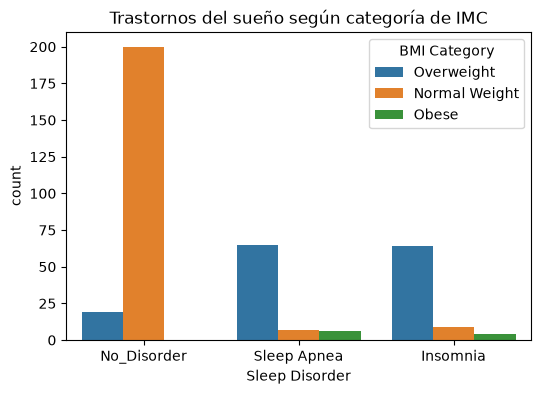

In [24]:
# visualizamos la comparación de cuantas personas tienen cada trastorno del sueño según su categoría de IMC
plt.figure(figsize=(6, 4))
sns.countplot(data=df_h4, x="Sleep Disorder", hue="BMI Category")
plt.title("Trastornos del sueño según categoría de IMC")
plt.savefig("../imagen/trastornos_sueno_imc.jpg")
plt.show()

In [25]:
#compruebo los resultados obtenidos en el gráfico
df_h4.value_counts()

BMI Category   Sleep Disorder
Normal Weight  No_Disorder       200
Overweight     Sleep Apnea        65
               Insomnia           64
               No_Disorder        19
Normal Weight  Insomnia            9
               Sleep Apnea         7
Obese          Sleep Apnea         6
               Insomnia            4
Name: count, dtype: int64

### Podemos obtener la relación entre las variables:
Según los datos registrados y mediante el cruce de las variables, determinamos que existe una relación bidireccional entre ambas, aunque no podemos concluir cuál ha provocado a cuál.

Se concluye que:
* De trastorno a peso: 9 de cada 10 personas con un trastorno diagnosticado tienen sobrepeso u obesidad (el "88.3%" en insomnio y el "91.0%" en apnea del sueño), frente a solo el "8.7%" en las personas sin trastorno.
* De peso a trastorno: Entre las personas con "sobrepeso", el "87.1%" presenta insomnio o apnea, y en "obesidad" sube al "100%" (teniendo en cuenta que la muestra de obesidad es de solo 10 registros). En cambio, en las personas con "peso normal" solo el "7.4%" tiene algún trastorno (el "92.6%" no presenta ninguno).
En el gráfico de barras ("Trastornos del sueño según categoría de IMC") se observa que el grupo sin trastornos ("No_Disorder") está formado casi por completo por personas con peso normal ("200" frente a solo "19" con sobrepeso y "0" con obesidad), mientras que en "Insomnio" y  Apnea" ocurre lo contrario y predomina el sobrepeso ("64" y "65" personas frente a "9" y "7" con peso normal). Además, aunque las barras de obesidad se ven bajas porque solo hay "10" registros en el estudio, todos ellos ("4" con insomnio y "6" con apnea) presentan algún trastorno del sueño.

## 8.5. Exploración de Nuevas Variables: 
#### Hipótesis 5 
 *"La ocupación profesional influye en los niveles de estrés como en la duración y calidad del sueño"*
* **Variables a considerar:** "Occupation", "Stress Level","Quality of Sleep","Sleep Duration"



In [26]:
# agrupo los datos por profesión, calculo el tamaño y las medias de estrés y sueño de cada una, las ordeno de mayor a menor estrés
df_h5 = df_limpio[["Occupation", "Stress Level", "Quality of Sleep", "Sleep Duration"]].copy()
resumen_h5 = df_h5.groupby("Occupation")[["Stress Level", "Quality of Sleep", "Sleep Duration"]].agg(["count", "mean"])
resumen_h5  = resumen_h5.sort_values(by=("Stress Level", "mean"), ascending=False)
print(resumen_h5.round(2))

                     Stress Level       Quality of Sleep       Sleep Duration  \
                            count  mean            count  mean          count   
Occupation                                                                      
Sales Representative            2  8.00                2  4.00              2   
Salesperson                    32  7.00               32  6.00             32   
Scientist                       4  7.00                4  5.00              4   
Doctor                         71  6.73               71  6.65             71   
Software Engineer               4  6.00                4  6.50              4   
Nurse                          73  5.55               73  7.37             73   
Lawyer                         47  5.06               47  7.89             47   
Manager                         1  5.00                1  7.00              1   
Accountant                     37  4.59               37  7.89             37   
Teacher                     

#plt.figure(figsize=(8, 5))
sns.barplot(data=df_h5, y="Occupation", x="Stress Level", order=resumen_h5.index)
plt.title("Nivel medio de estrés según profesión")
plt.show()

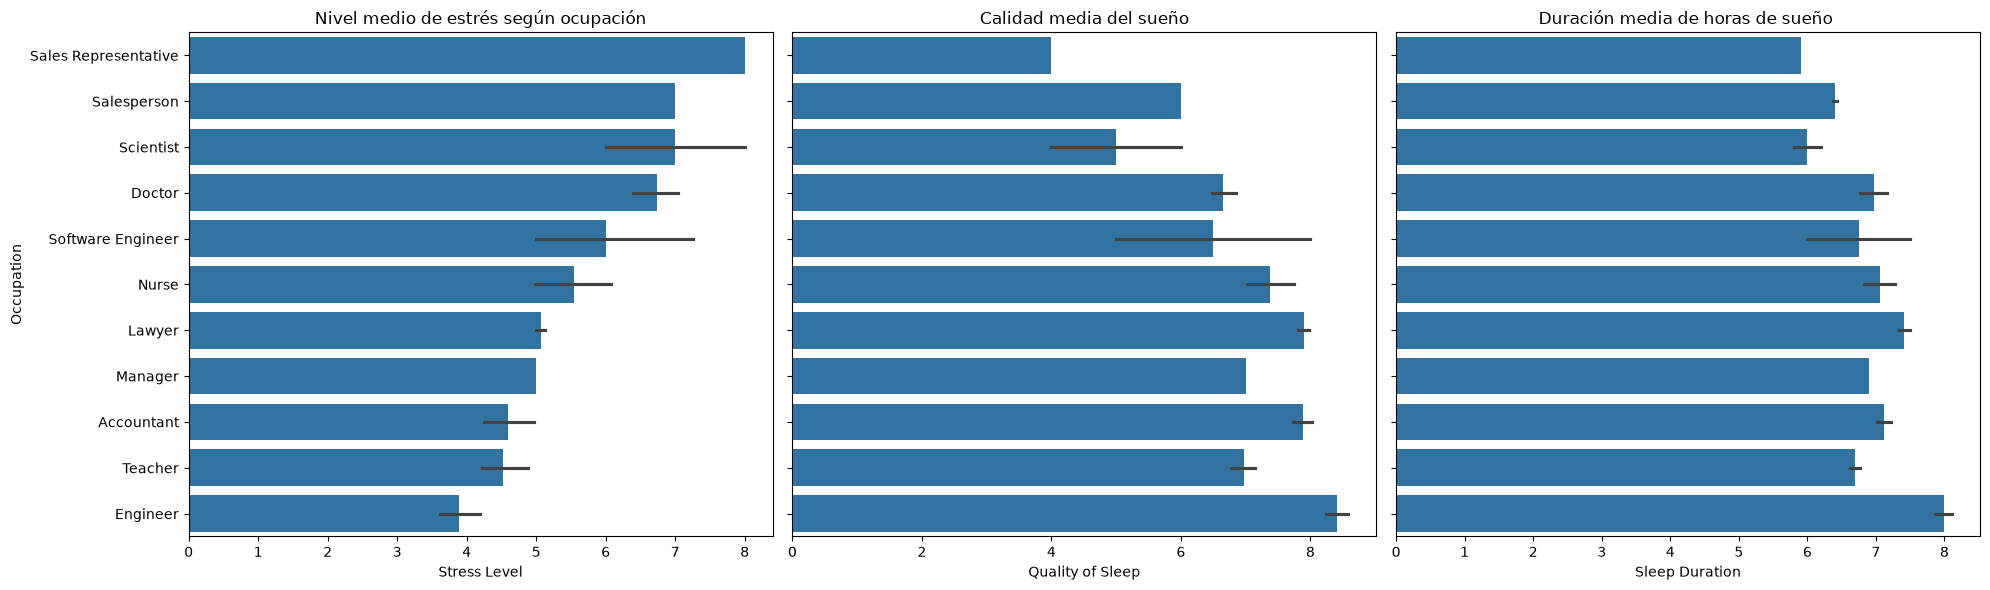

In [27]:
# Lienzo con 1 fila y 3 columnas compartiendo el eje Y (nombres de profesiones)
fig, ax = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

# Dibujamos gráfico de la media del nivel de stress,utilizaré data=df_h5 y que me lea order=resumen_h5.index que es donde tengo agrupadas las profesiones 
sns.barplot(data=df_h5, y="Occupation", x="Stress Level", order=resumen_h5.index, ax=ax[0])
ax[0].set_title("Nivel medio de estrés según ocupación")

# Dibujamos gráfico de la media de la calidad de sueño
sns.barplot(data=df_h5, y="Occupation", x="Quality of Sleep", order=resumen_h5.index, ax=ax[1])
ax[1].set_title("Calidad media del sueño")

# Dibujamos gráfico de la media de duración del sueño
sns.barplot(data=df_h5, y="Occupation", x="Sleep Duration", order=resumen_h5.index, ax=ax[2])
ax[2].set_title("Duración media de horas de sueño ")
plt.tight_layout() # Ajusta los espacios automáticamente para que los textos no se superpongan
plt.savefig("../imagen/estres_sueno_ocupacion.jpg")
plt.show()

### Podemos obtener la relación entre las variables:
En la media de la relación entre el nivel de estrés y la ocupación, obtenemos que las profesiones que experimentan mejores (menores) niveles de estrés son: "Engineer", "Teacher" y "Accountant". Sin embargo, observamos que las profesiones con peores niveles de estrés, así como peor calidad y duración del sueño, son: "Salesperson" y "Doctor". Podemos ver que "Sales Representative" (2 registros), "Scientist" (4), "Software Engineer" (4) y "Manager" (1) tienen muy pocos datos para sacar conclusiones generales.


## 8.6. Exploración de Nuevas Variables: 
#### Hipótesis 6 
 *"A menor edad incrementan los niveles de estrés y disminuye la duración y calidad del sueño"*
* **Variables a considerar:** "Age", "Stress Level","Quality of Sleep","Sleep Duration"

In [28]:
# agrupo los datos por edad, calculo el tamaño y las medias de estrés y sueño de cada una, las ordeno de mayor a menor estrés
df_h6 = df_limpio[["Age", "Stress Level", "Quality of Sleep", "Sleep Duration"]].copy()
df_h6['Grupo_Edad'] = pd.cut(   
    df_h6['Age'],
    bins=[20, 35, 45, 65],
    labels=['27-35 años', '36-45 años', '46+ años']) #tomo rango de edades para manipular mejor los datos
resumen_h6 = df_h6 .groupby("Grupo_Edad")[["Stress Level", "Quality of Sleep", "Sleep Duration"]].agg(["count", "mean"])
resumen_h6 = resumen_h6.sort_values(by=("Stress Level", "mean"), ascending=False)
print(resumen_h6.round(2))

           Stress Level       Quality of Sleep       Sleep Duration      
                  count  mean            count  mean          count  mean
Grupo_Edad                                                               
27-35 años           94  6.57               94  6.50             94  6.85
36-45 años          170  5.14              170  7.34            170  7.05
46+ años            110  4.75              110  7.96            110  7.50


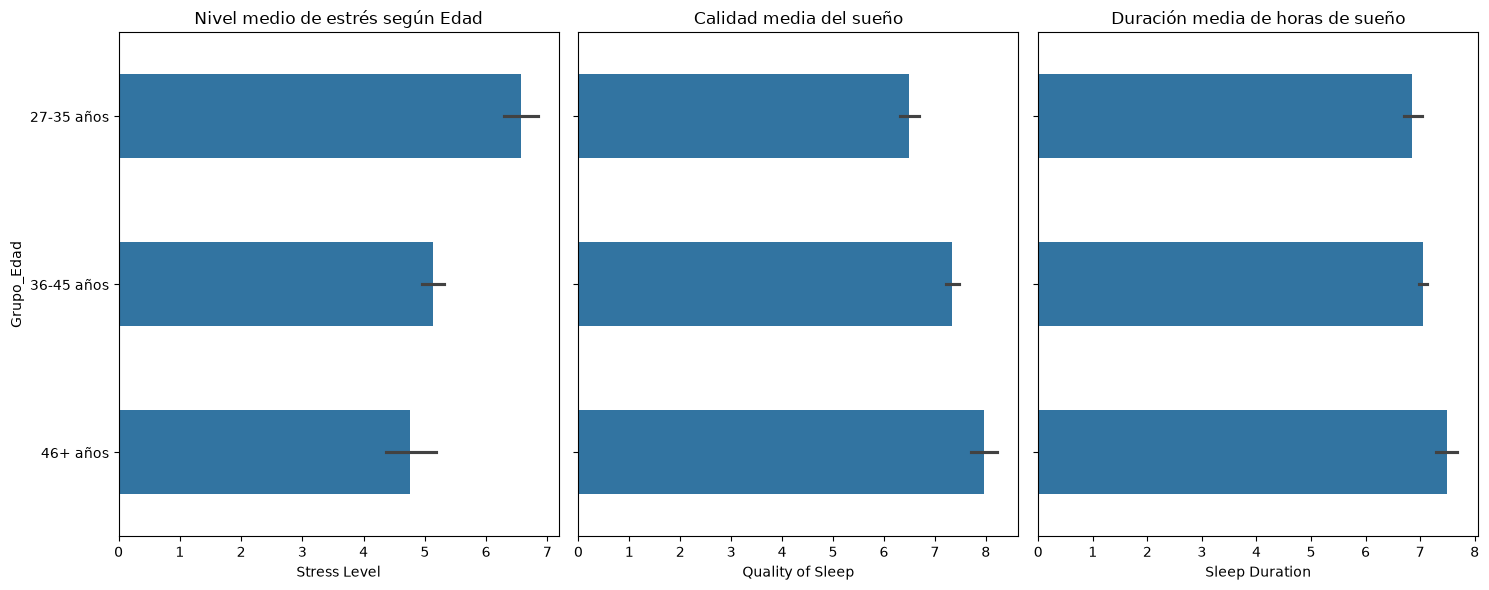

In [29]:
# Lienzo con 1 fila y 3 columnas compartiendo el eje Y (rango edades)
fig, ax = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

# Dibujamos gráfico de la media del nivel de stress,utilizaré data=df_h5 y que me lea order=resumen_h5.index que es donde tengo agrupadas las profesiones 
sns.barplot(data=df_h6, y="Grupo_Edad", x="Stress Level", order=resumen_h6.index, ax=ax[0],width=0.5)
ax[0].set_title("Nivel medio de estrés según Edad")

# Dibujamos gráfico de la media de la calidad de sueño
sns.barplot(data=df_h6, y="Grupo_Edad", x="Quality of Sleep", order=resumen_h6.index, ax=ax[1],width=0.5)
ax[1].set_title("Calidad media del sueño")

# Dibujamos gráfico de la media de duración del sueño
sns.barplot(data=df_h6, y="Grupo_Edad", x="Sleep Duration", order=resumen_h6.index, ax=ax[2],width=0.5)
ax[2].set_title("Duración media de horas de sueño")
plt.tight_layout() # Ajusta los espacios automáticamente para que los textos no se superpongan
plt.savefig("../imagen/estres_sueno_grupo_edad.jpg")
plt.show()

### Podemos obtener la relación entre las variables:
Se puede visualizar que a menor edad la media del nivel de estrés incrementa, mientras que la calidad y duración del sueño es menor para los intervalos de edad 27-35 años, por lo que podemos respaldar la hipótesis planteada, considerando que las medias son fiables dado que el número de registros tiene un tamaño adecuado para dicho análisis.
